# Do ENRICO design topics cluster in the embedding space?

This notebook matches RICO screen embeddings directly to the [ENRICO](https://github.com/luileito/enrico) annotations by global RICO `screen_id`. The local labels are a copy of ENRICO's official [`design_topics.csv`](https://github.com/luileito/enrico/blob/master/design_topics.csv), which assigns 1,460 curated screens to 20 mutually exclusive design topics. Each plotted point is one screen; there is no app-level averaging.

- **UMAP overview**: a single shared projection colored by ENRICO topic, with topic centroids labelled.
- **UMAP small multiples**: every topic is highlighted against the same faint background, with density contours and a centroid.
- **Neighborhood purity**: topic-level evidence measured in the original embedding space.
- **PCA and t-SNE**: secondary projection diagnostics rather than the main evidence.

The primary evidence is computed in the original normalized embedding space: topic neighborhood purity, its label-permutation baseline, and the cosine silhouette score. The projections are supporting visualizations; UMAP and t-SNE can make local gaps look more decisive than they are.

In [1]:
from __future__ import annotations

import ast
import csv
import json
import re
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

sns.set_theme(context="paper", style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

The default paths match the local RICO checkout. `EMBEDDINGS_PATH` may be a Hugging Face dataset saved to disk, a CSV/Parquet/JSONL table, a single NumPy file, or a directory of per-screen `.npy`/`.npz` files. This analysis uses the genuine one-token average-pooled embeddings instead of deriving them from a wider pooling run.

`ENRICO_TOPICS_PATH` points to the local copy of ENRICO's official `design_topics.csv`. All annotated screens are used; no topic-frequency filter or class balancing is applied.

In [2]:
RANDOM_STATE = 42
SCREEN2VEC_ROOT = Path(r"C:\Users\Jonathan\Dev\screen2vec-revisited")
EMBEDDINGS_PATH = SCREEN2VEC_ROOT / "embeddings_4096_Last"
ENRICO_TOPICS_PATH = SCREEN2VEC_ROOT / "enrico_design_topics.csv"
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "_screen2vec.tex").exists()), Path.cwd())
OUTPUT_DIR = PROJECT_ROOT / "overleaf" / "graphics" / "category_embedding_enrico_topics"

PCA_PRECOMPONENTS = 50
K_NEIGHBORS = 4
N_PERMUTATIONS = 500

for required in (EMBEDDINGS_PATH, ENRICO_TOPICS_PATH):
    if not required.exists():
        raise FileNotFoundError(f"Missing required input: {required}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Embeddings: {EMBEDDINGS_PATH}")
print(f"ENRICO:     {ENRICO_TOPICS_PATH}")
print(f"Outputs:    {OUTPUT_DIR.resolve()}")

Embeddings: C:\Users\Jonathan\Dev\screen2vec-revisited\embeddings_4096_Last
ENRICO:     C:\Users\Jonathan\Dev\screen2vec-revisited\enrico_design_topics.csv
Outputs:    C:\Users\Jonathan\Dev\screen2vec-revisited\overleaf\graphics\category_embedding_enrico_topics


## Match ENRICO topics to RICO screen IDs

ENRICO uses the same global screen identifiers as RICO, so the local `design_topics.csv` can be joined directly to embedding filenames. The labels are screen-level design topics such as `list`, `login`, `gallery`, and `tutorial`.

In [3]:
enrico_topics = pd.read_csv(ENRICO_TOPICS_PATH, dtype={"screen_id": "string", "topic": "string"})
if set(enrico_topics.columns) != {"screen_id", "topic"}:
    raise ValueError(f"Expected screen_id and topic columns, found {enrico_topics.columns.tolist()}")
enrico_topics = enrico_topics.dropna(subset=["screen_id", "topic"]).copy()
enrico_topics["screen_id"] = enrico_topics["screen_id"].str.strip()
enrico_topics["topic"] = enrico_topics["topic"].str.strip()
if enrico_topics["screen_id"].duplicated().any():
    duplicates = enrico_topics.loc[enrico_topics["screen_id"].duplicated(False), "screen_id"].tolist()
    raise ValueError(f"Duplicate ENRICO screen IDs: {duplicates[:10]}")

topic_counts = enrico_topics["topic"].value_counts().sort_values(ascending=False)
display(topic_counts.rename("screens").to_frame())
print(f"Loaded {len(enrico_topics):,} ENRICO labels across {enrico_topics['topic'].nunique()} topics.")

,screens
topic,
list,265
tutorial,163
gallery,144
login,141
form,103
settings,90
menu,79
bare,76
modal,67


Loaded 1,460 ENRICO labels across 20 topics.


## Load embeddings for the ENRICO screen IDs

The loader selects only the screen IDs listed by ENRICO and reads the genuine one-token average-pooled vector for each screen. It also checks for duplicate screen IDs and inconsistent dimensionality.

In [4]:
ID_COLUMNS = ("screen_id", "id", "screen", "path", "file", "filename", "source")
VECTOR_COLUMNS = ("embeddings_4096_avg", "embedding", "embeddings", "vector", "features")

def canonical_screen_id(value) -> str:
    return Path(str(value).replace("\\", "/")).stem

def as_vector(value) -> np.ndarray:
    if isinstance(value, str):
        text = value.strip()
        try:
            value = json.loads(text)
        except json.JSONDecodeError:
            try:
                value = ast.literal_eval(text)
            except (SyntaxError, ValueError):
                value = np.fromstring(text.strip("[]"), sep=",")
    array = np.asarray(value, dtype=np.float32).squeeze()
    if array.ndim == 2:
        array = array.mean(axis=0)
    if array.ndim != 1:
        raise ValueError(f"Expected a vector or matrix, got shape {array.shape}")
    return array

def columns_for(frame: pd.DataFrame) -> tuple[str, str]:
    id_col = next((c for c in ID_COLUMNS if c in frame.columns), None)
    vector_col = next((c for c in VECTOR_COLUMNS if c in frame.columns), None)
    if id_col is None or vector_col is None:
        if frame.shape[1] == 2:
            return frame.columns[0], frame.columns[1]
        raise ValueError(f"Could not identify ID/vector columns. Found: {frame.columns.tolist()}")
    return id_col, vector_col

def rows_from_frame(frame: pd.DataFrame, wanted: set[str]):
    id_col, vector_col = columns_for(frame)
    ids = frame[id_col].map(canonical_screen_id)
    for screen_id, value in zip(ids, frame[vector_col]):
        if screen_id in wanted:
            yield screen_id, as_vector(value)

def load_table(path: Path, wanted: set[str]):
    suffix = path.suffix.lower()
    if suffix == ".parquet":
        yield from rows_from_frame(pd.read_parquet(path), wanted)
    elif suffix in {".jsonl", ".json"}:
        yield from rows_from_frame(pd.read_json(path, lines=suffix == ".jsonl"), wanted)
    elif suffix == ".csv":
        with path.open("r", encoding="utf-8", errors="replace", newline="") as handle:
            first = next(csv.reader(handle))
        has_named_columns = any(name in first for name in (*ID_COLUMNS, *VECTOR_COLUMNS))
        kwargs = {} if has_named_columns else {"header": None, "names": ["screen_id", "embedding"]}
        for chunk in pd.read_csv(path, chunksize=1_000, **kwargs):
            yield from rows_from_frame(chunk, wanted)
    else:
        raise ValueError(f"Unsupported table format: {path}")

def load_array_file(path: Path) -> np.ndarray:
    loaded = np.load(path, allow_pickle=False)
    if isinstance(loaded, np.lib.npyio.NpzFile):
        preferred = next((key for key in VECTOR_COLUMNS if key in loaded.files), None)
        if preferred is None and len(loaded.files) == 1:
            preferred = loaded.files[0]
        if preferred is None:
            loaded.close()
            raise ValueError(f"Cannot choose a vector from {path}; keys={loaded.files}")
        array = loaded[preferred]
        loaded.close()
        return as_vector(array)
    return as_vector(loaded)

def rows_from_dataset(dataset, wanted: set[str]):
    columns = dataset.column_names
    id_col = next((c for c in ID_COLUMNS if c in columns), None)
    vector_col = next((c for c in VECTOR_COLUMNS if c in columns), None)
    if id_col is None or vector_col is None:
        raise ValueError(f"Could not identify ID/vector columns. Found: {columns}")
    for row in dataset:
        screen_id = canonical_screen_id(row[id_col])
        if screen_id in wanted:
            yield screen_id, as_vector(row[vector_col])

def rows_from_array_files(files: list[Path], wanted: set[str]):
    selected = [file for file in files if canonical_screen_id(file.stem) in wanted]
    def load_one(file: Path):
        return canonical_screen_id(file.stem), load_array_file(file)
    with ThreadPoolExecutor() as executor:
        yield from executor.map(load_one, selected)

def load_selected_embeddings(path: Path, wanted: set[str]) -> tuple[list[str], np.ndarray]:
    rows = {}
    table_suffixes = {".csv", ".parquet", ".json", ".jsonl"}
    if path.is_file() and path.suffix.lower() in table_suffixes:
        iterator = load_table(path, wanted)
    elif path.is_file() and path.suffix.lower() in {".npy", ".npz"}:
        archive = np.load(path, allow_pickle=False)
        if isinstance(archive, np.lib.npyio.NpzFile):
            iterator = ((canonical_screen_id(k), as_vector(archive[k])) for k in archive.files)
        else:
            raise ValueError("A single .npy needs IDs; use an .npz keyed by screen ID or per-screen files.")
    elif path.is_dir() and (path / "dataset_info.json").exists():
        from datasets import load_from_disk
        dataset = load_from_disk(str(path))
        if hasattr(dataset, "values"):
            parts = list(dataset.values())
            dataset = parts[0] if len(parts) == 1 else __import__("datasets").concatenate_datasets(parts)
        iterator = rows_from_dataset(dataset, wanted)
    elif path.is_dir():
        tables = [p for p in path.rglob("*") if p.suffix.lower() in table_suffixes]
        arrays = [p for p in path.rglob("*") if p.suffix.lower() in {".npy", ".npz"}]
        if tables:
            iterator = (row for table in tables for row in load_table(table, wanted))
        elif arrays:
            iterator = rows_from_array_files(arrays, wanted)
        else:
            raise FileNotFoundError(f"No supported embedding files found under {path}")
    else:
        raise FileNotFoundError(path)

    for screen_id, vector in tqdm(iterator, desc="Loading ENRICO embeddings"):
        if screen_id in wanted and screen_id not in rows:
            rows[screen_id] = vector
    if not rows:
        raise ValueError("No embeddings matched the selected RICO screen IDs. Check the ID column and paths.")
    dimensions = Counter(vector.size for vector in rows.values())
    if len(dimensions) != 1:
        raise ValueError(f"Inconsistent embedding dimensions: {dimensions}")
    ids = list(rows)
    return ids, np.stack([rows[screen_id] for screen_id in ids]).astype(np.float32)

wanted_ids = set(enrico_topics["screen_id"])
screen_ids, screen_vectors = load_selected_embeddings(EMBEDDINGS_PATH, wanted_ids)
print(f"Loaded {len(screen_ids):,}/{len(wanted_ids):,} selected screens; shape={screen_vectors.shape}.")

Loading ENRICO embeddings: 1342it [00:01, 1279.73it/s]

Loaded 1,342/1,460 selected screens; shape=(1342, 4096).


## Build the ENRICO screen analysis matrix

Each ENRICO screen keeps its own topic label and contributes one L2-normalized embedding. This preserves ENRICO's screen-level task semantics rather than assigning an app-wide label. Any annotation without an embedding is reported explicitly.

In [5]:
loaded = pd.DataFrame({"screen_id": screen_ids, "embedding": list(normalize(screen_vectors))})
screens = enrico_topics.merge(loaded, on="screen_id", how="inner", validate="one_to_one")
missing_ids = sorted(wanted_ids - set(screens["screen_id"]), key=int)
if missing_ids:
    print(f"Warning: {len(missing_ids):,} ENRICO screens have no embedding; first IDs: {missing_ids[:10]}")

X = np.stack(screens["embedding"]).astype(np.float32)
labels = screens["topic"].to_numpy()

display(screens["topic"].value_counts().rename("matched screens").to_frame())
print(f"Final analysis matrix: {X.shape[0]:,} screens × {X.shape[1]:,} dimensions")

,matched screens
topic,
list,249
tutorial,152
gallery,131
login,127
form,95
settings,82
menu,71
bare,71
modal,64


Final analysis matrix: 1,342 screens × 4,096 dimensions


## Quantify ENRICO topic structure in the original embedding space

Neighborhood purity is the fraction of each screen's nearest neighbors that share its ENRICO topic. The chance baseline accounts for the observed topic frequencies. The permutation test holds the embedding neighborhoods fixed and randomly shuffles topic labels.

In [6]:
k = min(K_NEIGHBORS, len(screens) - 1)
neighbors = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
neighbor_indices = neighbors.kneighbors(X, n_neighbors=k + 1, return_distance=False)[:, 1:]
point_purity = (labels[neighbor_indices] == labels[:, None]).mean(axis=1)
observed_purity = point_purity.mean()
frequencies = pd.Series(labels).value_counts(normalize=True)
chance_purity = float((frequencies ** 2).sum())

rng = np.random.default_rng(RANDOM_STATE)
null_purity = np.empty(N_PERMUTATIONS)
for i in range(N_PERMUTATIONS):
    shuffled = rng.permutation(labels)
    null_purity[i] = (shuffled[neighbor_indices] == shuffled[:, None]).mean()
p_value = (1 + np.count_nonzero(null_purity >= observed_purity)) / (N_PERMUTATIONS + 1)
silhouette = silhouette_score(X, labels, metric="cosine", sample_size=min(5_000, len(X)), random_state=RANDOM_STATE)

metrics = pd.DataFrame({
    "metric": [f"{k}-NN topic purity", "frequency chance purity", "permutation mean purity", "permutation p-value", "cosine silhouette"],
    "value": [observed_purity, chance_purity, null_purity.mean(), p_value, silhouette],
})
topic_metrics = (
    pd.DataFrame({"topic": labels, "neighbor_purity": point_purity})
    .groupby("topic")
    .agg(screens=("neighbor_purity", "size"), neighbor_purity=("neighbor_purity", "mean"))
    .sort_values("neighbor_purity", ascending=False)
)
topic_metrics["chance_purity"] = (topic_metrics["screens"] - 1) / (len(screens) - 1)
display(metrics.style.format({"value": "{:.4f}"}))
display(topic_metrics.style.format({"neighbor_purity": "{:.3f}", "chance_purity": "{:.3f}"}))
metrics.to_csv(OUTPUT_DIR / "enrico_topic_structure_metrics.csv", index=False)
topic_metrics.to_csv(OUTPUT_DIR / "enrico_topic_neighborhood_purity.csv")

,metric,value
0,4-NN topic purity,0.3312
1,frequency chance purity,0.0889
2,permutation mean purity,0.0885
3,permutation p-value,0.0020
4,cosine silhouette,-0.0208


,screens,neighbor_purity,chance_purity
topic,,,
camera,8,0.781,0.005
login,127,0.575,0.094
news,52,0.476,0.038
list,249,0.421,0.185
form,95,0.395,0.070
gallery,131,0.349,0.097
editor,18,0.333,0.013
mediaplayer,32,0.328,0.023
menu,71,0.306,0.052


## Compute PCA, t-SNE, and UMAP

t-SNE and UMAP operate on a 50-component PCA representation for speed and denoising. All random seeds are fixed. A shared palette keeps ENRICO topics consistent across panels.

In [7]:
n_precomponents = min(PCA_PRECOMPONENTS, X.shape[0] - 1, X.shape[1])
pca_pre = PCA(n_components=n_precomponents, random_state=RANDOM_STATE)
X_pca = pca_pre.fit_transform(X)
pca_2d = X_pca[:, :2]

perplexity = min(30, max(5, (len(X) - 1) // 3))
tsne_2d = TSNE(
    n_components=2, perplexity=perplexity, init="pca", learning_rate="auto",
    max_iter=1_000, random_state=RANDOM_STATE,
).fit_transform(X_pca)

umap_2d = umap.UMAP(
    n_components=2, n_neighbors=30, min_dist=0.15, metric="euclidean",
    random_state=RANDOM_STATE, n_jobs=1,
).fit_transform(X_pca)

projection = screens.drop(columns="embedding").copy()
projection[["pca_1", "pca_2"]] = pca_2d
projection[["tsne_1", "tsne_2"]] = tsne_2d
projection[["umap_1", "umap_2"]] = umap_2d
projection.to_csv(OUTPUT_DIR / "enrico_topic_projections.csv", index=False)
print(f"PC1 + PC2 explain {pca_pre.explained_variance_ratio_[:2].sum():.1%} of variance.")

PC1 + PC2 explain 6.4% of variance.


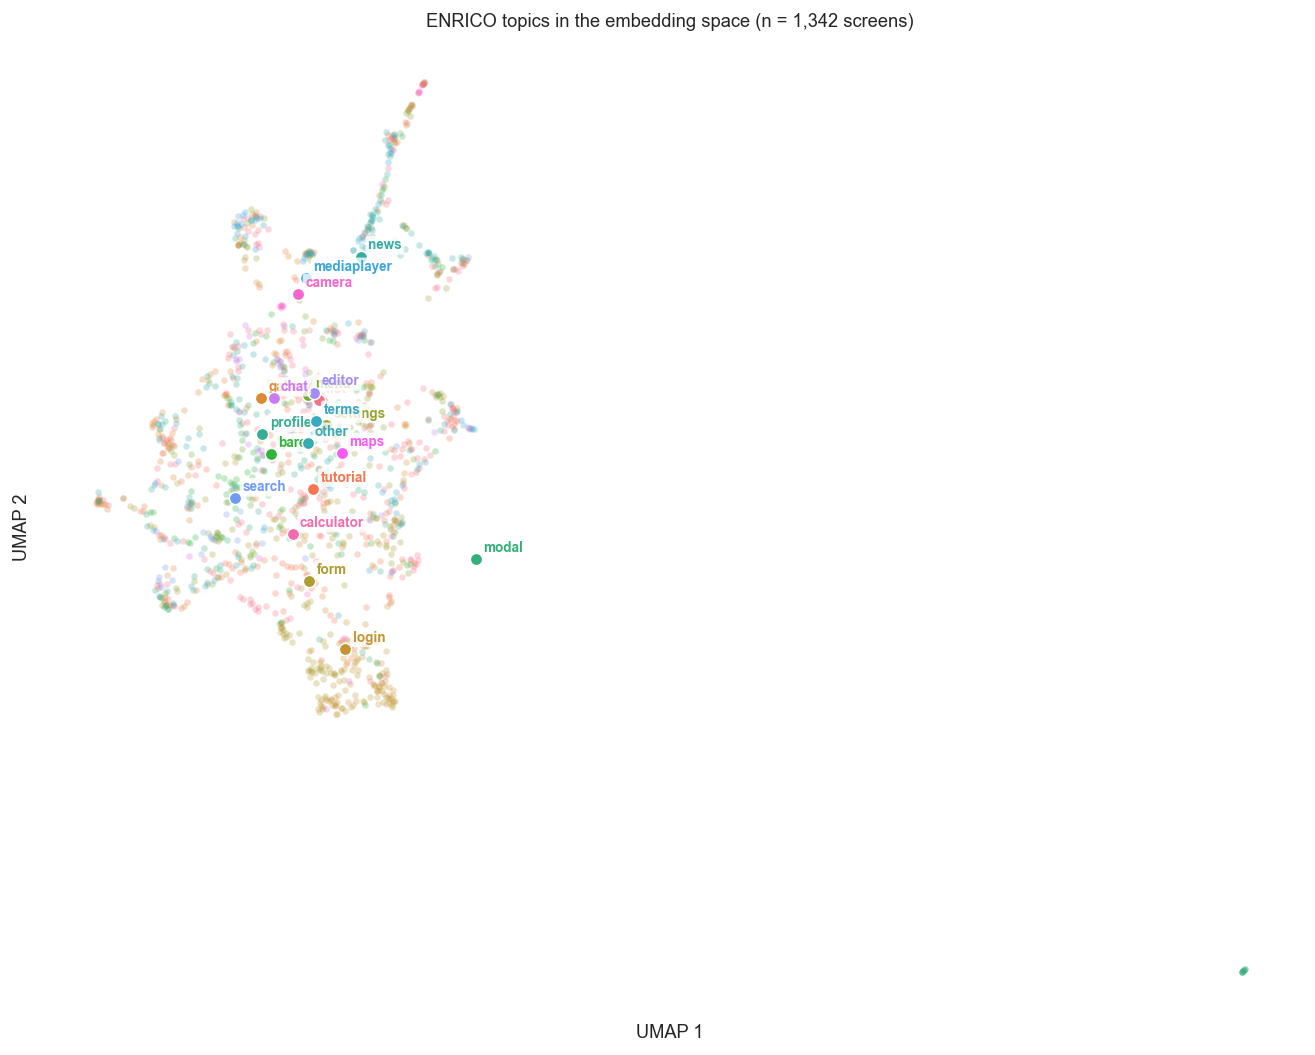

In [8]:
topic_order = projection["topic"].value_counts().index.tolist()
palette = dict(zip(topic_order, sns.color_palette("husl", len(topic_order))))
centroids = projection.groupby("topic")[["umap_1", "umap_2"]].mean()

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
for topic in topic_order:
    points = projection[projection["topic"] == topic]
    ax.scatter(
        points["umap_1"], points["umap_2"], s=13, alpha=0.28,
        color=palette[topic], linewidths=0, rasterized=True,
    )
for topic, (x, y) in centroids.loc[topic_order].iterrows():
    ax.scatter(x, y, s=46, color=palette[topic], edgecolor="white", linewidth=0.8, zorder=3)
    ax.annotate(
        topic, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=7.5, color=palette[topic],
        weight="semibold", bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.78},
    )
ax.set(title=f"ENRICO topics in the embedding space (n = {len(projection):,} screens)", xlabel="UMAP 1", ylabel="UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
sns.despine(ax=ax, left=True, bottom=True)
fig.savefig(OUTPUT_DIR / "enrico_topics_umap_overview.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "enrico_topics_umap_overview.pdf", bbox_inches="tight")
plt.show()

## ENRICO topic-highlight UMAP small multiples

Every panel uses the same coordinates and axis limits. All ENRICO screens remain visible in gray; the named topic is highlighted, its mean location is marked with a star, and KDE contours summarize its denser regions. This makes overlap and outliers visible without implying hard cluster boundaries.

Removed 11 isolated UMAP outlier(s).
      topic     umap_1    umap_2
128   modal  16.220068 -6.804307
556   modal  16.224728 -6.799695
11    modal  16.232437 -6.791862
534   modal  16.232851 -6.791540
190   modal  16.242868 -6.781457
465   modal  16.247866 -6.776529
795   modal  16.254101 -6.770333
375   modal  16.262594 -6.761784
403   modal  16.264122 -6.760270
1087  modal  16.276058 -6.748374
1178  modal  16.278919 -6.745540
UMAP-2 cutoff: -4.4575


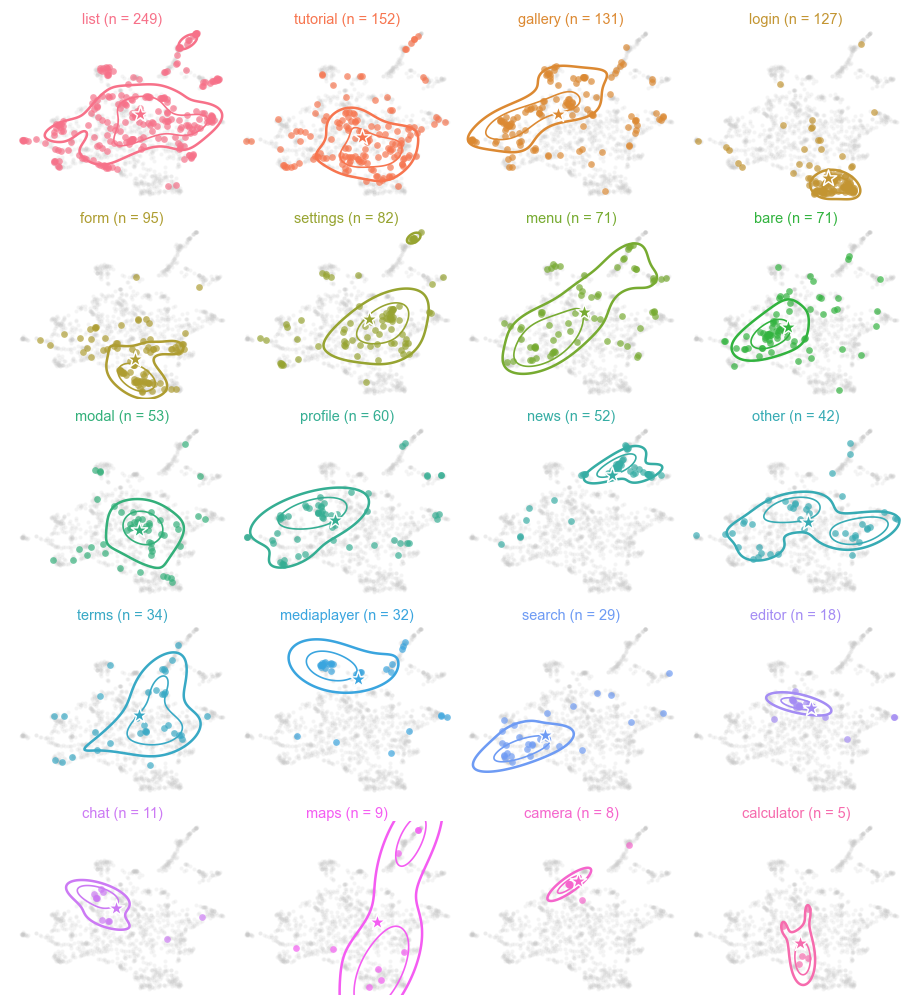

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Work on a copy so the original projection remains unchanged.
plot_projection = projection.copy()

# Remove isolated points below the main UMAP cloud.
#
# Instead of removing only the single minimum point, inspect the lowest
# 10% of UMAP-2 values and find the largest vertical gap. Everything below
# that gap is treated as the detached bottom outlier group.
sorted_y = np.sort(plot_projection["umap_2"].to_numpy())

lower_n = max(
    3,
    int(np.ceil(0.10 * len(sorted_y))),
)

lower_y = sorted_y[:lower_n]

gaps = np.diff(lower_y)

largest_gap_idx = int(np.argmax(gaps))

outlier_cutoff = (
    lower_y[largest_gap_idx]
    + lower_y[largest_gap_idx + 1]
) / 2.0

outlier_mask = (
    plot_projection["umap_2"]
    < outlier_cutoff
)

removed_outliers = (
    plot_projection
    .loc[outlier_mask]
    .copy()
)

plot_projection = (
    plot_projection
    .loc[~outlier_mask]
    .copy()
)

print(
    f"Removed {len(removed_outliers)} isolated UMAP outlier(s)."
)

if len(removed_outliers) > 0:
    print(
        removed_outliers[
            [
                "topic",
                "umap_1",
                "umap_2",
            ]
        ]
        .sort_values("umap_2")
        .to_string()
    )

print(
    f"UMAP-2 cutoff: {outlier_cutoff:.4f}"
)


# Recompute topic centroids after removing the outlier(s).
plot_centroids = (
    plot_projection
    .groupby("topic")[
        [
            "umap_1",
            "umap_2",
        ]
    ]
    .mean()
)


n_cols = 4

n_rows = int(
    np.ceil(
        len(topic_order) / n_cols
    )
)


# Approximately full ACM page width, while keeping enough vertical
# space on the page for the LaTeX caption.
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(7.0, 7.6),
    squeeze=False,
)

axes = axes.ravel()


x_range = (
    plot_projection["umap_1"].max()
    - plot_projection["umap_1"].min()
)

y_range = (
    plot_projection["umap_2"].max()
    - plot_projection["umap_2"].min()
)


x_pad = 0.04 * x_range
y_pad = 0.04 * y_range


x_limits = (
    plot_projection["umap_1"].min() - x_pad,
    plot_projection["umap_1"].max() + x_pad,
)

y_limits = (
    plot_projection["umap_2"].min() - y_pad,
    plot_projection["umap_2"].max() + y_pad,
)


for ax, topic in zip(
    axes,
    topic_order,
):

    focus = plot_projection[
        plot_projection["topic"] == topic
    ]

    # Background: all remaining screens.
    ax.scatter(
        plot_projection["umap_1"],
        plot_projection["umap_2"],
        s=5,
        color="#c7c7c7",
        alpha=0.18,
        linewidths=0,
        rasterized=True,
        zorder=1,
    )

    # Screens belonging to the current topic.
    ax.scatter(
        focus["umap_1"],
        focus["umap_2"],
        s=14,
        color=palette[topic],
        alpha=0.68,
        linewidths=0,
        rasterized=True,
        zorder=2,
    )

    # Topic density contours.
    if (
        focus["umap_1"].nunique() > 1
        and focus["umap_2"].nunique() > 1
    ):
        sns.kdeplot(
            data=focus,
            x="umap_1",
            y="umap_2",
            levels=[
                0.5,
                0.8,
            ],
            thresh=0.05,
            color=palette[topic],
            linewidths=(
                1.4,
                0.9,
            ),
            ax=ax,
            zorder=3,
        )

    # Topic centroid.
    centroid = plot_centroids.loc[topic]

    ax.scatter(
        centroid["umap_1"],
        centroid["umap_2"],
        marker="*",
        s=90,
        color=palette[topic],
        edgecolor="white",
        linewidth=0.8,
        zorder=4,
    )

    ax.set_xlim(x_limits)
    ax.set_ylim(y_limits)

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_title(
        f"{topic} (n = {len(focus)})",
        color=palette[topic],
        fontsize=8.0,
        pad=2.0,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    sns.despine(
        ax=ax,
        left=True,
        bottom=True,
    )


# Remove unused subplot axes.
for ax in axes[len(topic_order):]:
    ax.remove()


# Compact layout for a full-page ACM figure.
fig.subplots_adjust(
    left=0.015,
    right=0.995,
    bottom=0.01,
    top=0.99,
    wspace=0.03,
    hspace=0.14,
)


fig.savefig(
    OUTPUT_DIR
    / "enrico_topics_umap_small_multiples.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02,
)

fig.savefig(
    OUTPUT_DIR
    / "enrico_topics_umap_small_multiples.pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

## ENRICO topic neighborhood purity

This is the main topic-level comparison because it uses cosine neighbors in the original normalized embedding space, not distances in a two-dimensional projection. The ticks show the within-topic chance level implied by topic size; the dashed line is the overall observed purity.

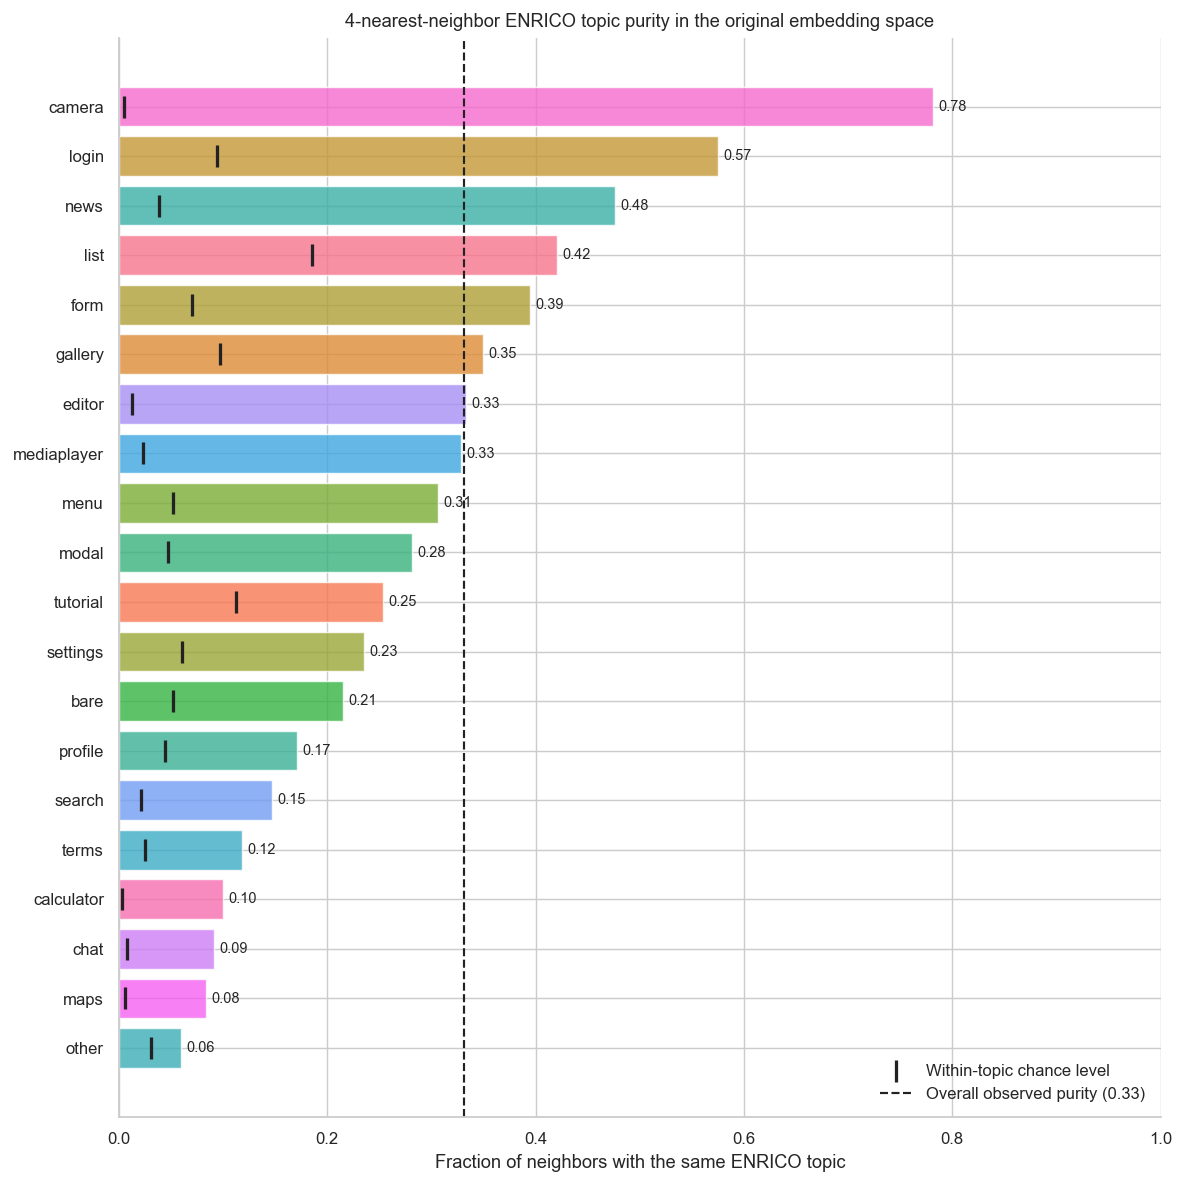

In [10]:
purity_plot = topic_metrics.reset_index().sort_values("neighbor_purity")
fig, ax = plt.subplots(figsize=(9, max(5, 0.45 * len(purity_plot))), constrained_layout=True)
bars = ax.barh(
    purity_plot["topic"], purity_plot["neighbor_purity"],
    color=[palette[t] for t in purity_plot["topic"]], alpha=0.78,
)
ax.scatter(
    purity_plot["chance_purity"], purity_plot["topic"], marker="|", s=150,
    color="#222222", linewidth=1.8, label="Within-topic chance level", zorder=3,
)
ax.axvline(observed_purity, color="#222222", linestyle="--", linewidth=1.2, label=f"Overall observed purity ({observed_purity:.2f})")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set(
    title=f"{k}-nearest-neighbor ENRICO topic purity in the original embedding space",
    xlabel="Fraction of neighbors with the same ENRICO topic", ylabel="", xlim=(0, 1),
)
ax.legend(frameon=False, loc="lower right")
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "enrico_topic_neighborhood_purity.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "enrico_topic_neighborhood_purity.pdf", bbox_inches="tight")
plt.show()

## Secondary projection diagnostics

PCA and t-SNE remain useful sensitivity checks, but they are shown separately from the primary UMAP views. Points use the same ENRICO topic colors as the overview. PCA preserves linear global variance; t-SNE emphasizes local neighborhoods, so distant island positions should not be interpreted.

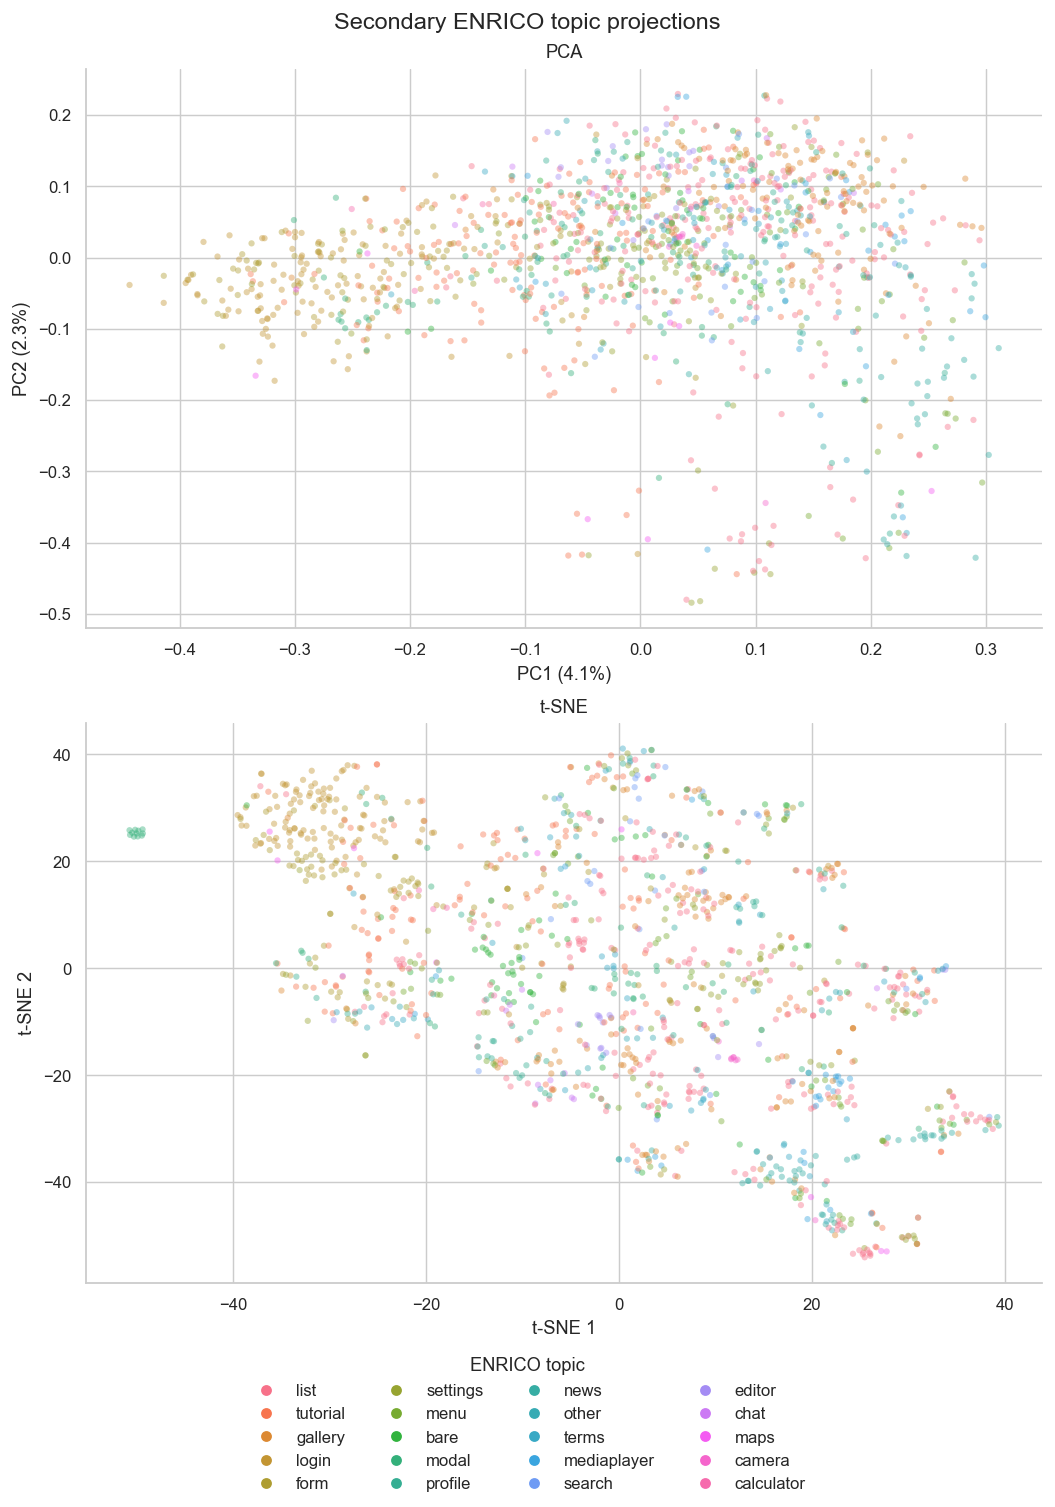

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(8, 11.5), constrained_layout=True)
diagnostics = [
    ("pca_1", "pca_2", "PCA", f"PC1 ({pca_pre.explained_variance_ratio_[0]:.1%})", f"PC2 ({pca_pre.explained_variance_ratio_[1]:.1%})"),
    ("tsne_1", "tsne_2", "t-SNE", "t-SNE 1", "t-SNE 2"),
]
for ax, (x, y, title, xlabel, ylabel) in zip(axes, diagnostics):
    sns.scatterplot(
        data=projection, x=x, y=y, hue="topic", hue_order=topic_order,
        palette=palette, s=12, alpha=0.42, linewidth=0, ax=ax, legend=False, rasterized=True,
    )
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    sns.despine(ax=ax)

handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=5, color=palette[t], label=t) for t in topic_order]
fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False, title="ENRICO topic")
fig.suptitle("Secondary ENRICO topic projections", fontsize=13)
fig.savefig(OUTPUT_DIR / "enrico_topics_pca_tsne_diagnostics.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "enrico_topics_pca_tsne_diagnostics.pdf", bbox_inches="tight")
plt.show()

## Reading the result

Evidence for ENRICO topic structure is strongest when neighborhood purity is clearly above both the frequency baseline and permutation distribution, the permutation p-value is small, and the silhouette score is positive. The faceted UMAP shows which topics contribute compact neighborhoods, which overlap, and where outliers occur.

A low PCA explained-variance percentage does not refute local topic structure: two linear components may retain little of a high-dimensional embedding. Conversely, visually separated t-SNE or UMAP islands alone are insufficient evidence because both methods can accentuate local gaps. Treat the original-space neighborhood-purity chart and metrics table as the primary evidence, with projections as supporting views.